# 4 · Modeling — PyMC-Marketing MMM


0. Loads hyperparameters from `03_tuning` (`best_params.json`) if available and validated on the hold-out set; otherwise, uses defaults.
1. Defines the model and performs a prior predictive check.
2. Fits the model on the training set and evaluates it on the **hold-out** set (last 90 days) against naive baselines.
3. Refits on the entire dataset, checking convergence (R-hat, ESS, divergences) and residuals.
4. Interprets the results: channel contributions, adstock, saturation curves, and **marginal CAC in a steady state**.
5. **Independent validation**: manually reproduces a channel's contribution from the raw formulas and compares it with the library's output.
6. Saves the fitted model for `05_scenarios`.

**Model Overview.** For each channel: spend → **adstock** (geometric decay, with `l_max` loaded from the selected tuning result, `alpha` parameter) → **saturation** (logistic, `lam`) → `beta` multiplier. To this, we add weekly and yearly seasonality (Fourier terms), event flags, discount, trend, and intercept. Target: `New customers` scaled to [0, 1] (divided by the maximum); likelihood: Normal.

In [1]:
import os, sys
from pathlib import Path
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# --- Colab ---
#PROJECT_DIR = "/content/drive/MyDrive/digis"
#  local ---
PROJECT_DIR = "."

if IN_COLAB:
    drive.mount("/content/drive")
root = Path(PROJECT_DIR).resolve()
if not (root / "notebooks").exists() and (root.parent / "notebooks").exists():
    root = root.parent
assert (root / "notebooks" / "common.py").exists(), (
    f"Not found {root}/notebooks/common.py.")
os.chdir(root / "notebooks"); sys.path.insert(0, str(root / "notebooks"))
print("root :", root, "| Colab:", IN_COLAB)

Mounted at /content/drive
root : /content/drive/MyDrive/digis | Colab: True


In [2]:
# Install PyMC-Marketing (not pre-installed in Colab). Tested version: 1.3.0
import importlib.util
if importlib.util.find_spec("pymc_marketing") is None:
    get_ipython().run_line_magic("pip", "install -q pymc-marketing==1.3.0")
    print("Installed. If you encounter an ImportError next, go to Runtime → Restart session and rerun the notebook.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.21.0 requires h5py<3.15.0,>=3.11.0, but you have h5py 3.16.0 which is incompatible.
Installed. If you encounter an ImportError next, go to Runtime → Restart session and rerun the notebook.


In [3]:
import os, json, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
import arviz as az
from scipy import stats
from pymc_marketing.mmm import MMM, GeometricAdstock, LogisticSaturation
from common import OUT_DIR, TARGET_CAC, make_mmm, OPTIONAL_CONTROLS
warnings.filterwarnings("ignore"); pd.set_option("display.width",160); pd.set_option("display.max_columns",30)

cfg = json.load(open(OUT_DIR/"config.json"))
df  = pd.read_csv(OUT_DIR/"model_input.csv", parse_dates=["date"])
CH, CT0 = cfg["channels"], cfg["controls"]
_bp = OUT_DIR/"best_params.json"
PARAMS = json.load(open(_bp))["chosen"] if _bp.exists() else dict(k_yearly=cfg["k_yearly"], l_max=14, saturation="logistic", beta_sigma=0.5, bf_features="peak")
K, L_MAX, SATURATION, BETA_SIGMA = PARAMS["k_yearly"], PARAMS["l_max"], PARAMS["saturation"], PARAMS["beta_sigma"]
CT = CT0 + OPTIONAL_CONTROLS[PARAMS["bf_features"]]
print("Hyperparameters:", PARAMS, "| source:", "03_tuning" if _bp.exists() else "default")
SPLIT = pd.Timestamp(cfg["holdout_start"])
COLS  = ["date"]+CH+CT
print(df.shape, "| channels:", CH, "\n| controls:", CT, "\n| hold-out from", SPLIT.date())

# ---- sampler parameters ----
SEED = 42
CHAINS, DRAWS, TUNE = 4, 1000, 1000
TARGET_ACCEPT = 0.9
CORES = max(1, min(CHAINS, os.cpu_count() or 1))
SAMPLER = dict(chains=CHAINS, draws=DRAWS, tune=TUNE, target_accept=TARGET_ACCEPT, cores=CORES, random_seed=SEED, progressbar=False)

def build(tight=True, beta_sigma=None):
    return make_mmm(CH, CT, K, L_MAX, SATURATION, BETA_SIGMA if beta_sigma is None else beta_sigma, tight_priors=tight)

train = df[df.date<SPLIT].reset_index(drop=True); hold = df[df.date>=SPLIT].reset_index(drop=True)
print("train", len(train), "| hold-out", len(hold))

Hyperparameters: {'k_yearly': 6, 'l_max': 21, 'saturation': 'logistic', 'beta_sigma': 0.5489779514362569, 'bf_features': 'peak+window'} | source: 03_tuning
(730, 20) | channels: ['bing', 'google', 'meta', 'pinterest'] 
| controls: ['dow_1', 'dow_2', 'dow_3', 'dow_4', 'dow_5', 'dow_6', 'bf_cm_peak', 'promo', 't', 'xmas_eve_day', 'new_year', 'bf_window'] 
| hold-out from 2026-07-03
train 640 | hold-out 90


## Specification and Priors
The library's default priors proved to be **too wide for our target** (see prior predictive check below: they allow thousands of customers per day against an actual mean of ≈ 400). Therefore, the priors have been scaled to a [0, 1] range:

| Parameter | Prior | Rationale / Meaning |
|---|---|---|
| `adstock_alpha` | Beta(1, 3) | Default; mean 0.25 → short memory/tail |
| `saturation_lam` | Gamma(3, 1) | Default; saturation speed |
| `saturation_beta` | HalfNormal(`beta_sigma`) | **Modified** (default σ=2): maximum channel effect; `beta_sigma` is a hyperparameter from `03_tuning` |
| `gamma_control` | Normal(0, 0.3) | **Modified** (default σ=2): control variables effect |
| `gamma_fourier` | Laplace(0, 0.1) | **Modified** (default b=1): seasonality coefficients |
| `intercept` | Normal(0.2, 0.1) | **Modified** (default N(0,2)): baseline ≈ 0.2 × max |
| noise `y_sigma` | HalfNormal(0.05) | **Modified** (default σ=2) |

These are weakly informative priors: they rule out absurd values without pre-determining the outcome. Sensitivity to priors is evaluated in `05_scenarios`.

In [4]:
m0 = build()
cfg_priors = getattr(m0, "model_config", None) or m0.default_model_config
for k,v in cfg_priors.items(): print(f"{k:16s} {v}")
print("\nsaturation:",SATURATION,"| beta_sigma:",BETA_SIGMA)

intercept        Prior("Normal", mu=0.2, sigma=0.1)
likelihood       Prior("Normal", sigma=Prior("HalfNormal", sigma=0.05), dims="date")
gamma_control    Prior("Normal", mu=0, sigma=0.3, dims="control")
gamma_fourier    Prior("Laplace", mu=0, b=0.1, dims="fourier_mode")
adstock_alpha    Prior("Beta", alpha=1, beta=3, dims="channel")
saturation_lam   Prior("Gamma", alpha=3, beta=1, dims="channel")
saturation_beta  Prior("HalfNormal", sigma=0.5489779514362569, dims="channel")

saturation: logistic | beta_sigma: 0.5489779514362569


### Prior predictive check
Do the priors generate plausible values *before* the model sees the data?

**How to read the plot:** Each line represents a single draw from the priors — showing "what the model would consider possible without data." The initial version of the plot looked like a solid barcode band: the default priors allowed noise up to thousands of customers **independently every day** and seasonality of ±thousands, causing lines to jump between −6,000 and +12,000. This is not a code bug, but a signal that the priors are excessively wide. Below: a 90% uncertainty band comparing default and our scaled priors on the same scale.

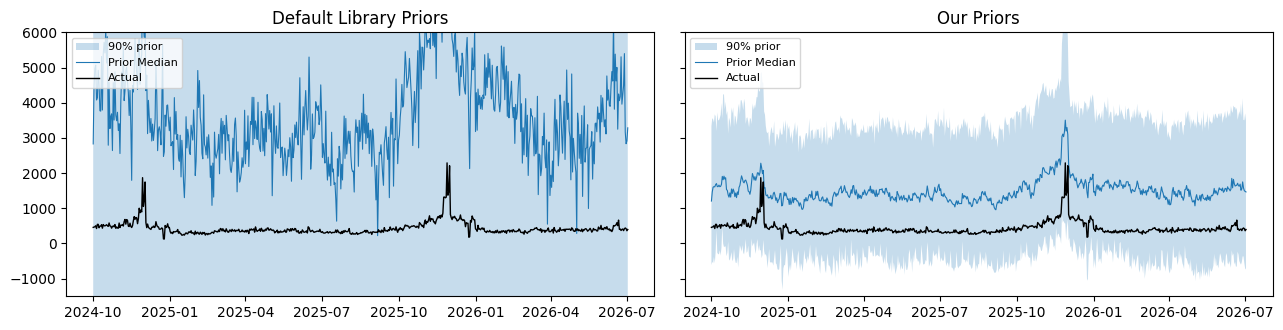

Default Library Priors       90% mean prior forecast: -4978 … 12754 | within [0.25x;4x] of actual (433): 9%
Our Priors                   90% mean prior forecast: 525 … 2725 | within [0.25x;4x] of actual (433): 67%


In [5]:
def prior_draws(tight, beta_sigma):
    mp = build(tight=tight, beta_sigma=beta_sigma)
    pri = mp.sample_prior_predictive(train[COLS], train["new"], samples=300, extend_idata=False, combined=False, random_seed=SEED)["y"]
    S_ = float(mp.get_scales_as_xarray()["target_scale"]); return pri.values.reshape(-1,len(train))*S_
obs = train.new.mean(); out_={}
fig,ax=plt.subplots(1,2,figsize=(13,3.4),sharey=True)
for a_,(lab,tight,bs) in zip(ax,[("Default Library Priors",False,2.0),("Our Priors",True,BETA_SIGMA)]):
    v=prior_draws(tight,bs); mm=v.mean(1); lo,md_,hi=np.percentile(v,[5,50,95],axis=0)
    a_.fill_between(train.date,lo,hi,alpha=.25,label="90% prior"); a_.plot(train.date,md_,lw=.8,label="Prior Median"); a_.plot(train.date,train.new,"k",lw=1,label="Actual")
    a_.set_ylim(-1500,6000); a_.set_title(lab); a_.legend(loc="upper left",fontsize=8)
    out_[lab]=(np.percentile(mm,[5,95]).round(0), float(np.mean((mm>.25*obs)&(mm<4*obs))))
plt.tight_layout(); plt.show()
for k,(rng,fr) in out_.items(): print(f"{k:28s} 90% mean prior forecast: {rng[0]:.0f} … {rng[1]:.0f} | within [0.25x;4x] of actual ({obs:.0f}): {fr:.0%}")

### Prior predictive interpretation: decision check
A narrower prior is not automatically a plausible prior. The cell below compares the prior's mean daily forecast with the observed training mean and prints a verdict computed from the current run, so this text cannot go stale after a rerun. If the check fails, revisit the prior scales in `common.py` or the `beta_sigma` range in `3_tuning` and rerun the hold-out comparison. Do not tune priors solely to make the plot look good: document the rationale.

In [6]:
# Compact, explicit prior-scale diagnostic (uses the prior draws from the cell above).
prior_rows = []
for label, (rng, fraction) in out_.items():
    prior_rows.append({
        "prior": label,
        "mean daily customers: 5th pct": float(rng[0]),
        "mean daily customers: 95th pct": float(rng[1]),
        "observed training mean": float(obs),
        "P(mean in 0.25x–4x observed)": float(fraction),
    })
display(pd.DataFrame(prior_rows).round(2))
print("Interpretation: a narrow prior is not automatically a plausible prior; compare its absolute scale with observed customers.")

# Data-driven verdict (thresholds are judgement calls, stated here so they can be challenged)
rng_, frac_ = out_["Our Priors"]
covers = rng_[0] <= obs <= rng_[1]
verdict = "PASS" if (frac_ >= 0.5 and covers) else ("PASS WITH WARNING" if frac_ >= 0.5 else "FAIL")
print(f"\nPrior predictive verdict: {verdict}")
print(f"- share of prior draws with mean daily forecast within 0.25x-4x of the observed mean ({obs:.0f}): {frac_:.0%} (criterion: >= 50%)")
print(f"- observed mean inside the prior 90% interval {rng_[0]:.0f} ... {rng_[1]:.0f}: {covers}")
if verdict == "PASS WITH WARNING":
    side = "above" if obs < rng_[0] else "below"
    print(f"The prior is plausible in scale but centred {side} the observed level (media effects are added on top of the intercept). The posterior is data-dominated, but state this in the write-up.")
if verdict == "FAIL":
    print("Treat this as an unresolved modelling issue; do not describe the prior check as successful.")

,prior,mean daily customers: 5th pct,mean daily customers: 95th pct,observed training mean,P(mean in 0.25x–4x observed)
0,Default Library Priors,-4978.0,12754.0,433.42,0.09
1,Our Priors,525.0,2725.0,433.42,0.67


Interpretation: a narrow prior is not automatically a plausible prior; compare its absolute scale with observed customers.

Prior predictive verdict: PASS WITH WARNING
- share of prior draws with mean daily forecast within 0.25x-4x of the observed mean (433): 67% (criterion: >= 50%)
- observed mean inside the prior 90% interval 525 ... 2725: False
The prior is plausible in scale but centred above the observed level (media effects are added on top of the intercept). The posterior is data-dominated, but state this in the write-up.


## Training on Train and Testing on Hold-out
The hold-out consists of the last 90 days, excluding Black Friday and major holidays, to evaluate performance during a "normal" operating period. For forecasting, we use `include_last_observations=True` so that the adstock accounts for the spend tail from the end of the training set.
We benchmark against a **naive forecast**: the average of the last 4 matching weekdays from the training set.

**Caveat:** the same hold-out was also used in `3_tuning` to accept or reject the tuned configuration, so the score below is slightly optimistic. A cleaner estimate would need a further untouched period.

In [7]:
mmm_tr = build()
idata_tr = mmm_tr.fit(train[COLS], train["new"], **SAMPLER)

def diagnostics(idata, label):
    names=[n for n in ["adstock_alpha","saturation_lam","saturation_slope","saturation_kappa","saturation_beta","gamma_control","gamma_fourier","intercept_contribution","y_sigma"] if n in idata.posterior]
    s = az.summary(idata.posterior, var_names=names)
    div = int(idata["sample_stats"]["diverging"].sum())
    print(f"[{label}] divergences: {div} | max R-hat: {s['r_hat'].max():.3f} | min ESS bulk: {s['ess_bulk'].min():.0f} | min ESS tail: {s['ess_tail'].min():.0f}")
    return s
s_tr = diagnostics(idata_tr, "train")

Output()

[train] divergences: 0 | max R-hat: 1.006 | min ESS bulk: 609 | min ESS tail: 444


**Interpretation guardrail.** Report point accuracy and interval calibration separately. With only 90 hold-out days, calibration estimates are noisy, and 100% coverage of a nominal 90% interval is not proof of optimal calibration. The cell after the hold-out results prints the interpretation for the current run.

Output()

                  MAPE    RMSE
MMM              0.074  36.931
Naive (Weekday)  0.124  55.757
90% interval coverage: 100% (expected ~90%)


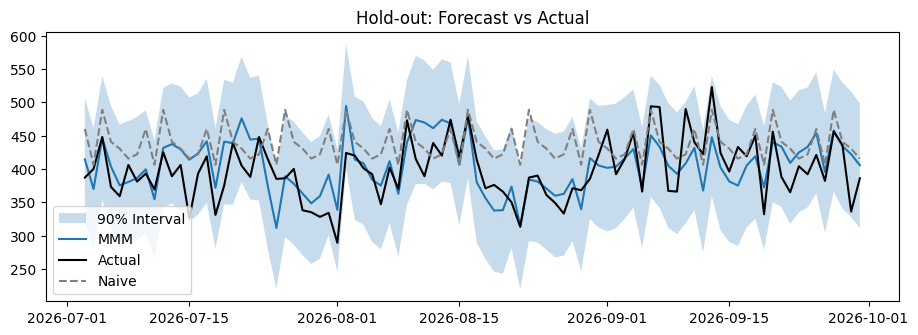

In [8]:
St = float(mmm_tr.get_scales_as_xarray()["target_scale"])
ppc = mmm_tr.sample_posterior_predictive(hold[COLS], extend_idata=False, combined=False,
                                         include_last_observations=True, random_seed=SEED)["y"]*St
yp = ppc.values.reshape(-1,len(hold)); mean=yp.mean(0); lo,hi=np.percentile(yp,[5,95],axis=0)
y = hold.new.values
mape=lambda p:np.mean(np.abs(p-y)/y); rmse=lambda p:np.sqrt(np.mean((p-y)**2))
# naive: average of the last 4 matching weekdays from train
last=train.tail(28).assign(dow=lambda d:d.date.dt.dayofweek); naive=hold.date.dt.dayofweek.map(last.groupby("dow").new.mean()).values
res = pd.DataFrame({"MAPE":[mape(mean),mape(naive)],"RMSE":[rmse(mean),rmse(naive)]},index=["MMM","Naive (Weekday)"]).round(3)
cover = np.mean((y>=lo)&(y<=hi))
print(res); print(f"90% interval coverage: {cover:.0%} (expected ~90%)")
fig,ax=plt.subplots(figsize=(11,3.5)); ax.fill_between(hold.date,lo,hi,alpha=.25,label="90% Interval"); ax.plot(hold.date,mean,label="MMM"); ax.plot(hold.date,y,"k",label="Actual"); ax.plot(hold.date,naive,"--",c="gray",label="Naive"); ax.legend(); ax.set_title("Hold-out: Forecast vs Actual"); plt.show()
HOLDOUT_METRICS = dict(mape_mmm=float(mape(mean)), mape_naive=float(mape(naive)), rmse_mmm=float(rmse(mean)), rmse_naive=float(rmse(naive)), coverage90=float(cover))

In [9]:
m_ = HOLDOUT_METRICS
gain_mape = 1 - m_["mape_mmm"] / m_["mape_naive"]; gain_rmse = 1 - m_["rmse_mmm"] / m_["rmse_naive"]
print(f"MMM vs weekday-naive on the hold-out: MAPE {m_['mape_mmm']:.1%} vs {m_['mape_naive']:.1%} ({gain_mape:+.0%} relative), RMSE {m_['rmse_mmm']:.1f} vs {m_['rmse_naive']:.1f} ({gain_rmse:+.0%}).")
c_ = m_["coverage90"]
print(f"Nominal 90% interval covers {c_:.0%} of hold-out days:", "close to nominal." if abs(c_ - 0.9) <= 0.05 else ("intervals look too wide (conservative)." if c_ > 0.95 else "intervals look too narrow (overconfident)."))
print("The hold-out period contains no Black Friday or holidays, so this says nothing about event periods; see the residuals by event day below.")

MMM vs weekday-naive on the hold-out: MAPE 7.4% vs 12.4% (+40% relative), RMSE 36.9 vs 55.8 (+34%).
Nominal 90% interval covers 100% of hold-out days: intervals look too wide (conservative).
The hold-out period contains no Black Friday or holidays, so this says nothing about event periods; see the residuals by event day below.


## Final Model on Full Dataset
For the scenario analysis (`05_scenarios`), we need a model trained on the entire dataset, including September 2026.

In [10]:
mmm = build()
idata = mmm.fit(df[COLS], df["new"], **SAMPLER)
s_full = diagnostics(idata, "final")
S = float(mmm.get_scales_as_xarray()["target_scale"]); CS = mmm.get_scales_as_xarray()["channel_scale"].sel(channel=CH).values
P = idata.posterior
s_full.loc[[i for i in s_full.index if i.startswith(("adstock","saturation","y_sigma","intercept"))]].round(3)

Output()

[final] divergences: 0 | max R-hat: 1.008 | min ESS bulk: 782 | min ESS tail: 1190


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
adstock_alpha[bing],0.054,0.057,0.0027,0.16,2292,1598,1.00,0.00092,0.0015
adstock_alpha[google],0.169,0.135,0.011,0.43,1246,1689,1.00,0.0036,0.0017
adstock_alpha[meta],0.308,0.149,0.051,0.52,989,1190,1.00,0.0049,0.002
adstock_alpha[pinterest],0.136,0.141,0.008,0.42,2966,2146,1.00,0.0025,0.0034
saturation_lam[bing],0.99,0.6,0.26,2.1,1817,1490,1.00,0.012,0.012
saturation_lam[google],4.2,2.84,0.61,9.1,783,1665,1.01,0.1,0.034
saturation_lam[meta],2.28,1.12,0.76,4.2,782,1740,1.00,0.041,0.013
saturation_lam[pinterest],1.61,1.13,0.37,3.7,2222,2053,1.00,0.023,0.026
saturation_beta[bing],0.141,0.11,0.041,0.36,1440,1581,1.00,0.003,0.0037
saturation_beta[google],0.141,0.137,0.05,0.41,808,1612,1.01,0.0043,0.0046


### Residuals: Is there any uncaptured structure left in the model?

### What this model cannot prove

The hold-out test evaluates predictive performance, not causal identification. Spend may move with demand, promotions, inventory, or other unobserved factors. A strong fit and a good hold-out score do not prove that the estimated media contribution is incremental. Treat channel response curves as decision-support hypotheses and validate material reallocations with controlled tests or geo/holdout experiments.

R² in-sample: 0.930 | MAPE: 0.069 | ACF(1)=0.03, ACF(7)=-0.04
Top-8 residuals:
      date  new     mu  resid
2025-12-01 2209 1780.0  429.0
2025-11-29 1372 1769.0 -397.0
2025-11-30 1470 1851.0 -381.0
2024-11-30 1053 1416.0 -363.0
2025-11-28 2290 1972.0  318.0
2024-11-29 1870 1556.0  314.0
2024-12-02 1748 1472.0  276.0
2024-12-01 1229 1426.0 -197.0


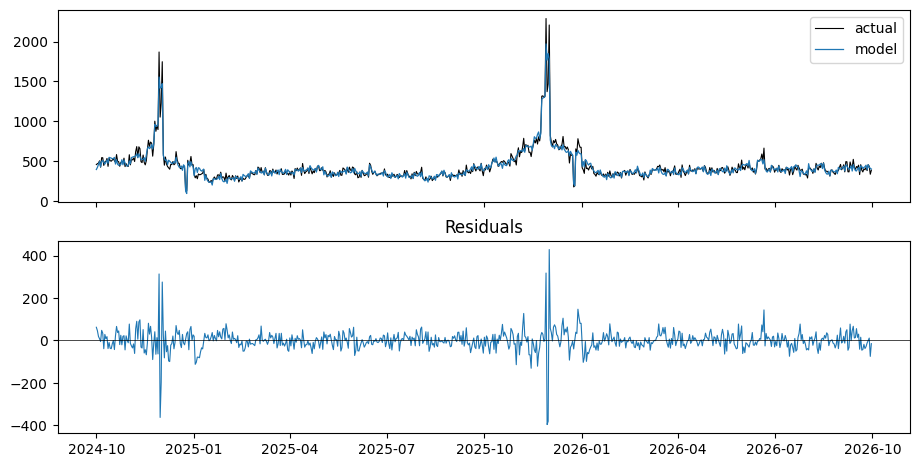

In [11]:
mu = P["mu"].mean(("chain","draw")).values*S
res_ = df.new.values-mu
ss_res=((df.new-mu)**2).sum(); ss_tot=((df.new-df.new.mean())**2).sum()
acf1=pd.Series(res_).autocorr(1); acf7=pd.Series(res_).autocorr(7)
print(f"R² in-sample: {1-ss_res/ss_tot:.3f} | MAPE: {np.mean(np.abs(res_)/df.new):.3f} | ACF(1)={acf1:.2f}, ACF(7)={acf7:.2f}")
print("Top-8 residuals:"); print(df.assign(mu=mu.round(0),resid=res_.round(0)).loc[np.abs(res_).argsort()[::-1][:8],["date","new","mu","resid"]].to_string(index=False))
fig,ax=plt.subplots(2,1,figsize=(11,5.5),sharex=True); ax[0].plot(df.date,df.new,"k",lw=.8,label="actual"); ax[0].plot(df.date,mu,lw=.9,label="model"); ax[0].legend()
ax[1].plot(df.date,res_,lw=.8); ax[1].axhline(0,c="k",lw=.5); ax[1].set_title("Residuals"); plt.show()

### Two further residual checks
**Yearly seasonality amplitude.** A zero-mean periodic term sums to about zero over whole years, so its *sum* says nothing about its size. We report its range per day instead.

**Residuals on Black Friday weekend.** One flag for the four days (plus the window flag) cannot reproduce the shape inside the weekend: Friday and Monday are typically higher than Saturday and Sunday. If the residuals below have opposite signs for those groups, the model under-predicts the peak days and over-predicts the weekend, and the `bf_day` / `cm_day` flags (`peak+window+bf+cm` in `3_tuning`) are worth testing.

In [12]:
seas_name = "yearly_seasonality_contribution" if "yearly_seasonality_contribution" in P else None
if seas_name:
    fs = P[seas_name].mean(("chain", "draw")).values * S
    print(f"Yearly seasonality: {fs.min():.0f} ... {fs.max():.0f} customers/day (peak-to-peak {fs.max() - fs.min():.0f}); sum over the period {fs.sum():.0f} (≈0 by construction)")
grp = pd.Series("other days", index=df.index)
if "bf_window" in df: grp[(df.bf_window == 1) & (df.bf_cm_peak == 0)] = "window before BF"
grp[(df.bf_cm_peak == 1)] = "BF weekend: Sat/Sun"
if "bf_day" in df: grp[df.bf_day == 1] = "Black Friday day"
if "cm_day" in df: grp[df.cm_day == 1] = "Cyber Monday day"
rb = pd.DataFrame({"group": grp, "resid": res_, "pct": res_ / df.new.values}).groupby("group").agg(days=("resid", "size"), mean_resid=("resid", "mean"), mean_pct=("pct", "mean")).round(3)
display(rb.loc[[g for g in ["Black Friday day", "Cyber Monday day", "BF weekend: Sat/Sun", "window before BF", "other days"] if g in rb.index]])

Yearly seasonality: -90 ... 182 customers/day (peak-to-peak 271); sum over the period -35 (≈0 by construction)


,days,mean_resid,mean_pct
group,,,
Black Friday day,2,316.222,0.153
Cyber Monday day,2,352.681,0.176
BF weekend: Sat/Sun,4,-334.673,-0.264
window before BF,8,-0.444,-0.005
other days,714,-0.004,-0.006


## Interpretation


### Parameters: Did the data actually "teach" the model beyond the prior?
If the posterior spread is almost identical to the prior, the data does not identify the parameter — and conclusions drawn from it should be treated with caution.

In [13]:
from scipy import stats as st

In [14]:
prior_sd = {"adstock_alpha": st.beta(1,3).std(), "saturation_lam": st.gamma(3,scale=1).std(), "saturation_beta": st.halfnorm(scale=BETA_SIGMA).std()}
rows=[]
for p in [n for n in ["adstock_alpha","saturation_lam","saturation_slope","saturation_kappa","saturation_beta"] if n in P]:
    for ch in CH:
        x=P[p].sel(channel=ch).values.ravel(); rows.append((p,ch,x.mean(),np.percentile(x,5),np.percentile(x,95),x.std()/prior_sd.get(p,np.nan)))
tab=pd.DataFrame(rows,columns=["parameter","channel","mean","5%","95%","sd_post/sd_prior"]).round(3); print(tab.to_string(index=False))
a=P["adstock_alpha"].values.reshape(-1,len(CH)); hl=np.log(.5)/np.log(np.clip(a,1e-6,.999999))
print("\nAdstock half-life (days), median [5–95%]:"); print(pd.DataFrame({ch:[f"{np.median(hl[:,i]):.1f} [{np.percentile(hl[:,i],5):.1f}–{np.percentile(hl[:,i],95):.1f}]"] for i,ch in enumerate(CH)},index=["half-life"]).T)

      parameter   channel  mean    5%   95%  sd_post/sd_prior
  adstock_alpha      bing 0.054 0.002 0.168             0.296
  adstock_alpha    google 0.169 0.010 0.436             0.699
  adstock_alpha      meta 0.308 0.048 0.527             0.771
  adstock_alpha pinterest 0.136 0.007 0.439             0.730
 saturation_lam      bing 0.987 0.252 2.102             0.347
 saturation_lam    google 4.206 0.592 9.197             1.637
 saturation_lam      meta 2.276 0.741 4.248             0.646
 saturation_lam pinterest 1.606 0.357 3.826             0.652
saturation_beta      bing 0.141 0.040 0.367             0.331
saturation_beta    google 0.141 0.050 0.430             0.414
saturation_beta      meta 0.337 0.158 0.727             0.570
saturation_beta pinterest 0.108 0.024 0.304             0.317

Adstock half-life (days), median [5–95%]:
               half-life
bing       0.2 [0.1–0.4]
google     0.3 [0.2–0.8]
meta       0.6 [0.2–1.1]
pinterest  0.3 [0.1–0.8]


### Decomposition of New Customers: Baseline / Media / Controls / Seasonality

In [15]:
T=len(df)
cc = P["channel_contribution"].sum("date")*S                          # (chain,draw,channel)
media = cc.sum("channel").values.ravel(); tot = df.new.sum()
comp = {"media (4 channels)":media}
for v,lab in (("control_contribution","controls (discount, events, week, trend)"),("yearly_seasonality_contribution","yearly seasonality"),("intercept_contribution","intercept")):
    if v in P:
        x=P[v]; x=x.sum("date") if "date" in x.dims else x*T
        if "control" in x.dims: x=x.sum("control")
        comp[lab]=(x*S).values.ravel()
out=pd.DataFrame({k:[v.mean(),np.percentile(v,5),np.percentile(v,95),v.mean()/tot] for k,v in comp.items()},index=["sum (customers)","5%","95%","share"]).T.round(2); print(out)
print("\nMedia accounts for",f"{media.mean()/tot:.0%} of all new customers (90%: {np.percentile(media,5)/tot:.0%}–{np.percentile(media,95)/tot:.0%})")

sp=df[CH].sum()
eff=pd.DataFrame({"spend £":sp.round(0),"spend share":(sp/sp.sum()).round(3),
   "customers (mean)":[cc.sel(channel=c).values.mean() for c in CH],
   "5%":[np.percentile(cc.sel(channel=c).values,5) for c in CH],"95%":[np.percentile(cc.sel(channel=c).values,95) for c in CH]}).round({"spend £":0,"spend share":3,"customers (mean)":0,"5%":0,"95%":0})
eff["avg £/customer"]=(eff["spend £"]/eff["customers (mean)"]).round(1)
print("\nNOTE: 'avg £/customer' is the AVERAGE CAC of the channel, not the marginal one. The £40 threshold applies to marginal CAC.\n"); print(eff)

                                          sum (customers)         5%        95%  share
media (4 channels)                              153529.58  132782.61  176336.93   0.49
controls (discount, events, week, trend)          4236.39   -4210.52   12376.30   0.01
yearly seasonality                                 -35.31     -50.29     -20.14  -0.00
intercept                                       155514.89  134336.74  174497.02   0.50

Media accounts for 49% of all new customers (90%: 42%–56%)

NOTE: 'avg £/customer' is the AVERAGE CAC of the channel, not the marginal one. The £40 threshold applies to marginal CAC.

             spend £  spend share  customers (mean)       5%      95%  avg £/customer
bing        242284.0        0.055           24120.0  14974.0  32955.0            10.0
google     1676880.0        0.383           43447.0  30069.0  62725.0            38.6
meta       2099197.0        0.479           71868.0  62844.0  82112.0            29.2
pinterest   364680.0        0.083   

### Saturation Curves and Marginal CAC in Steady State
Under **constant** daily spend `x`, the adstock with normalized weights equals `x`, meaning the channel response has a closed form:

`customers/day(x) = beta · S · tanh(lam · x / (2 · c))`, where `S` is the target scale and `c` is the channel scale (since (1−e^(−z))/(1+e^(−z)) = tanh(z/2)).

Marginal CAC = 1 / (d customers / d x) = 1 / ( beta · S · lam/(2c) · sech²(lam·x/(2c)) ).
This represents the **long-term** marginal CAC (after the carry-over effect has stabilized); finite windows and specific scenarios are analyzed in `05_scenarios`.

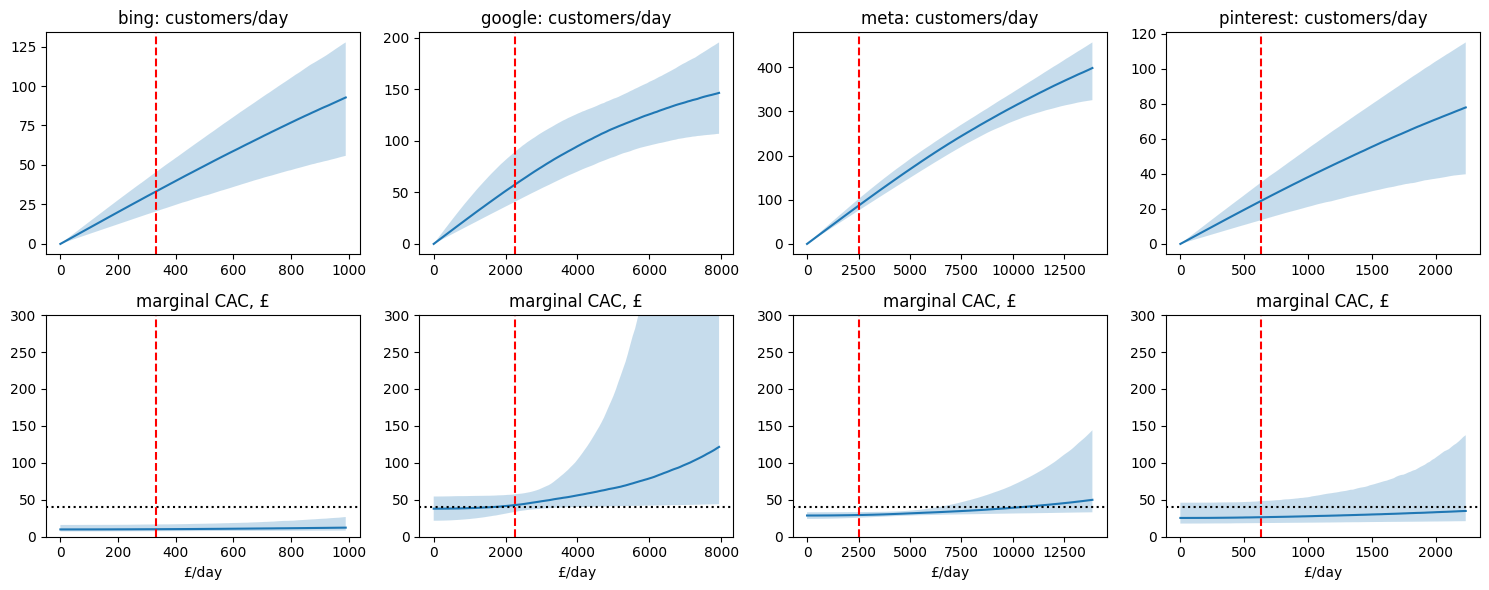

  channel level  £/day  med. marg. CAC    5%   95%  P(<£40)
     bing  base    331           10.19  7.46 16.63     1.00
     bing  +20%    398           10.31  7.54 16.88     1.00
   google  base   2265           42.88 33.61 57.43     0.33
   google  +20%   2718           45.87 36.73 60.83     0.16
     meta  base   2509           29.36 25.69 33.37     1.00
     meta  +20%   3011           29.67 26.29 33.48     1.00
pinterest  base    635           26.42 18.44 48.40     0.89
pinterest  +20%    761           26.81 18.65 49.54     0.88


In [16]:
if SATURATION == "logistic":
    base = cfg["baseline_daily_spend"]
    beta=P["saturation_beta"].values.reshape(-1,len(CH)); lam=P["saturation_lam"].values.reshape(-1,len(CH))
    def mcac(x, i):      # x — £/day, i — channel index; returns vector across draws
        z=lam[:,i]*x/(2*CS[i]); return 1.0/(beta[:,i]*S*lam[:,i]/(2*CS[i])/np.cosh(z)**2)
    def resp(x,i): return beta[:,i]*S*np.tanh(lam[:,i]*x/(2*CS[i]))
    fig,ax=plt.subplots(2,4,figsize=(15,6))
    rows=[]
    for i,ch in enumerate(CH):
        xs=np.linspace(0,df[ch].quantile(.99)*1.3,120)
        R=np.array([resp(x,i) for x in xs]); M=np.array([mcac(x,i) for x in xs])
        ax[0,i].fill_between(xs,*np.percentile(R,[5,95],axis=1),alpha=.25); ax[0,i].plot(xs,np.median(R,1)); ax[0,i].axvline(base[ch],c="r",ls="--"); ax[0,i].set_title(f"{ch}: customers/day");
        ax[1,i].fill_between(xs,*np.percentile(M,[5,95],axis=1),alpha=.25); ax[1,i].plot(xs,np.median(M,1)); ax[1,i].axhline(TARGET_CAC,c="k",ls=":"); ax[1,i].axvline(base[ch],c="r",ls="--"); ax[1,i].set_ylim(0,300); ax[1,i].set_xlabel("£/day"); ax[1,i].set_title("marginal CAC, £")
        for lab,mult in (("base",1.0),("+20%",1.2)):
            v=mcac(base[ch]*mult,i); rows.append((ch,lab,round(base[ch]*mult),np.median(v),np.percentile(v,5),np.percentile(v,95),np.mean(v<TARGET_CAC)))
    plt.tight_layout(); plt.show()
    mt=pd.DataFrame(rows,columns=["channel","level","£/day","med. marg. CAC","5%","95%",f"P(<£{TARGET_CAC})"]).round(2); print(mt.to_string(index=False))
else:
    print("Closed-form response derived for logistic saturation; for Hill, see scenario analysis in 05_scenarios.")

## Independent Validation: Manually Reproducing Channel Contribution
We take a **single** parameter draw from the posterior, calculate the adstock (normalized geometric weights, causal convolution with a zero start) and logistic saturation using our own code, and compare it with what the library returns. If they match, we understand exactly what the model is computing.

In [17]:
if SATURATION == "logistic":
    def manual_contribution(x_scaled, alpha, lam, beta, l_max=L_MAX):
        w = alpha**np.arange(l_max); w = w / w.sum()                 # geometric weights, normalized
        ad = np.convolve(x_scaled, w)[:len(x_scaled)]                # adstock: x_t + alpha·x_{t-1} + … (normalized)
        return beta * (1 - np.exp(-lam * ad)) / (1 + np.exp(-lam * ad))  # logistic saturation, then beta multiplier
    c0, d0 = 0, 5; chk = {}
    for i, ch in enumerate(CH):
        g = lambda n: float(P[n].sel(channel=ch).isel(chain=c0, draw=d0))
        lib = P["channel_contribution"].sel(channel=ch).isel(chain=c0, draw=d0).values
        man = manual_contribution(df[ch].values / CS[i], g("adstock_alpha"), g("saturation_lam"), g("saturation_beta"))
        chk[ch] = float(np.abs(lib - man).max())
    print("Max |library − manual| by channel:", {k: f"{v:.1e}" for k, v in chk.items()})
    assert max(chk.values()) < 1e-8, "Manual calculation does not match the library!"
    print("OK: manual calculation matches the library")
else:
    print("Closed-form response derived for logistic saturation; for Hill, see scenario analysis in 05_scenarios.")

Max |library − manual| by channel: {'bing': '1.7e-17', 'google': '2.1e-17', 'meta': '8.3e-17', 'pinterest': '1.4e-17'}
OK: manual calculation matches the library


## Saving

In [18]:
OUT_DIR.mkdir(parents=True,exist_ok=True)
mmm.save(str(OUT_DIR/"mmm_final.nc"))
meta=dict(params=PARAMS, controls=CT, holdout=HOLDOUT_METRICS, sampler=dict(chains=CHAINS,draws=DRAWS,tune=TUNE,target_accept=TARGET_ACCEPT,seed=SEED), l_max=L_MAX, k_yearly=K,
          target_scale=S, channel_scale=dict(zip(CH,map(float,CS))), pymc_marketing="1.3.0")
json.dump(meta,open(OUT_DIR/"model_meta.json","w"),indent=2,ensure_ascii=False)
print("Saved:",OUT_DIR/"mmm_final.nc"); print(json.dumps(HOLDOUT_METRICS,indent=2))

Saved: /content/drive/MyDrive/digis/data/processed/mmm_final.nc
{
  "mape_mmm": 0.0742299639858371,
  "mape_naive": 0.12354923243450112,
  "rmse_mmm": 36.93096262131729,
  "rmse_naive": 55.75675718890243,
  "coverage90": 1.0
}
